# Load Database

pada tahap ini kita akan memproses memunculkan data set terlebih dahulu yang telah aa di folder data/raw

In [11]:
from pathlib import Path
import pandas as pd 

# Mendukung notebook yang dijalankan dari folder utama atau notebooks.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "bank-full.csv"

df_raw = pd.read_csv(data_path, sep=";")

print(f"Baris: {df_raw.shape[0]:,}")
print(f"Kolom: {df_raw.shape[1]}")

df_raw.head()

Baris: 45,211
Kolom: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Process: audit kualitas data

pada tahap ini akan di lakukan pengeekan kualitas data mulai dari pengecekan missing value, tipe data, duplikasi data dll

In [12]:
# Ringkasan kualitas data per kolom
data_quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "unknown": df_raw.eq("unknown").sum(),
    "unique_values": df_raw.nunique(),
})

display(data_quality)

# Periksa baris identik dan distribusi hasil kampanye
print("Baris identik tambahan:", df_raw.duplicated().sum())
display(df_raw["y"].value_counts(dropna=False))


,dtype,missing,unknown,unique_values
age,int64,0,0,77
job,str,0,288,12
marital,str,0,0,3
education,str,0,1857,4
default,str,0,0,2
balance,int64,0,0,7168
housing,str,0,0,2
loan,str,0,0,2
contact,str,0,13020,3
day,int64,0,0,31


Baris identik tambahan: 0


y
no     39922
yes     5289
Name: count, dtype: int64

# Analyze: hitung tingkat konversi keseluruhan.

In [13]:
# Buat salinan agar data mentah tetap utuh.
df = df_raw.copy()

# Ubah hasil kampanye menjadi angka: 1 = berlangganan, 0 = tidak.
df["converted"] = df["y"].map({"yes": 1, "no": 0})

# Hentikan eksekusi jika ada nilai kosong atau selain yes/no.
assert df["converted"].notna().all(), "Kolom y berisi nilai selain yes/no."

# Hitung jumlah catatan dan jumlah konversi (nilai 1).
total_records = len(df)
conversions = df["converted"].sum()

# Rata-rata kolom 0/1 sama dengan proporsi catatan yang berakhir dengan konversi.
conversion_rate = df["converted"].mean()

# Tampilkan jumlah catatan, jumlah konversi, dan persentasenya.
print(f"Total catatan: {total_records:,}")
print(f"Jumlah konversi: {conversions:,}")
print(f"Tingkat konversi: {conversion_rate:.2%}")

Total catatan: 45,211
Jumlah konversi: 5,289
Tingkat konversi: 11.70%


## Kelompokkan catatan berdasarkan jenis kontak
Tujuan: Membandingkan jumlah catatan, jumlah konversi, dan tingkat konversi berdasarkan jenis kontak.

In [14]:
# Gunakan kolom converted: 1 berarti berlangganan, 0 berarti tidak.
contact_summary = df.groupby("contact")["converted"].agg(
    records="size",          # Jumlah catatan dalam kelompok.
    conversions="sum",       # Jumlah nilai 1, yaitu jumlah konversi.
    conversion_rate="mean",  # Proporsi nilai 1 dalam kelompok.
)

# Urutkan dari tingkat konversi tertinggi ke terendah.
contact_summary = contact_summary.sort_values(
    "conversion_rate", ascending=False
)

# Rapikan tampilan angka tanpa mengubah nilai di tabel asli.
display(contact_summary.style.format({
    "records": "{:,}",
    "conversions": "{:,}",
    "conversion_rate": "{:.2%}",
}))

,records,conversions,conversion_rate
contact,,,
cellular,"29,285","4,369",14.92%
telephone,"2,906",390,13.42%
unknown,"13,020",530,4.07%


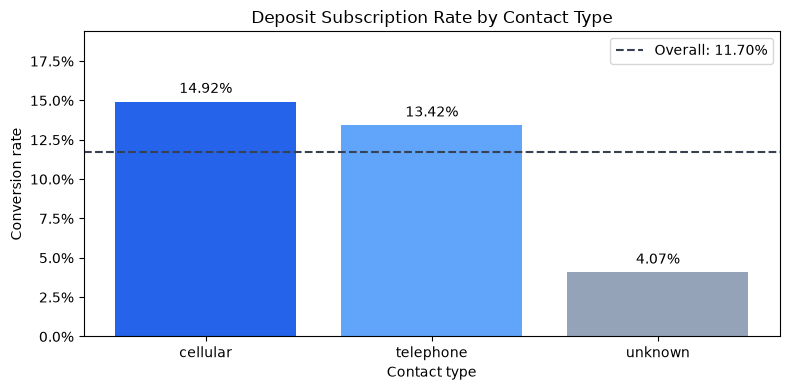

In [15]:
#melakukan visualisasi untuk membandingkan 3 kelompok
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt

# Buat grafik batang dari tingkat konversi tiap kelompok.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    contact_summary.index,
    contact_summary["conversion_rate"],
    color=["#2563EB", "#60A5FA", "#94A3B8"],
)

# Tampilkan persentase di atas setiap batang.
ax.bar_label(
    bars,
    labels=[f"{rate:.2%}" for rate in contact_summary["conversion_rate"]],
    padding=4,
)

# Tambahkan garis pembanding dari tingkat konversi seluruh catatan.
ax.axhline(
    conversion_rate,
    color="#374151",
    linestyle="--",
    label=f"Overall: {conversion_rate:.2%}",
)

# Format sumbu sebagai persen karena nilai aslinya berupa proporsi 0–1.
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, contact_summary["conversion_rate"].max() * 1.3)
ax.set_title("Deposit Subscription Rate by Contact Type")
ax.set_xlabel("Contact type")
ax.set_ylabel("Conversion rate")
ax.legend()

plt.tight_layout()
plt.show()

cellular memiliki tingkat konversi tertinggi (14,92%) dan menyumbang konversi terbanyak (4.369). Tingkatnya sekitar 1,50 poin persentase di atas telephone (13,42%). Keduanya berada di atas tingkat konversi keseluruhan, yaitu 11,70%.

Kategori unknown mencakup 13.020 catatan (28,80% dari data) dengan tingkat konversi 4,07%. Pertahankan kategori ini di grafik karena jumlahnya besar, tetapi baca sebagai jenis kontak tidak diketahui, bukan sebagai kanal tersendiri. Hasil ini juga belum menunjukkan bahwa mengganti kanal ke cellular akan meningkatkan konversi.

## konversi berdasarkan jumlah kontak
apakah tingkat konversi berbeda antara catatan dengan satu kali kontak dan catatan dengan beberapa kali kontak?


In [16]:
# Kelompokkan jumlah kontak tanpa mengubah kolom campaign asli.
contact_frequency = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, float("inf")],
    labels=["1", "2", "3", "4–5", "6+"],
)

# Hitung jumlah catatan, jumlah konversi, dan proporsi konversi per kelompok.
frequency_summary = (
    df.groupby(contact_frequency, observed=True)["converted"]
    .agg(records="size", conversions="sum", conversion_rate="mean")
    .rename_axis("contacts")
)

# Pastikan semua catatan masuk ke salah satu kelompok.
assert frequency_summary["records"].sum() == len(df), (
    "Ada nilai campaign yang tidak masuk ke kelompok jumlah kontak."
)

# Tampilkan tingkat konversi sebagai persentase tanpa mengubah nilai aslinya.
display(frequency_summary.style.format({
    "records": "{:,}",
    "conversions": "{:,}",
    "conversion_rate": "{:.2%}",
}))

,records,conversions,conversion_rate
contacts,,,
1,"17,544","2,561",14.60%
2,"12,505","1,401",11.20%
3,"5,521",618,11.19%
4–5,"5,286",456,8.63%
6+,"4,355",253,5.81%


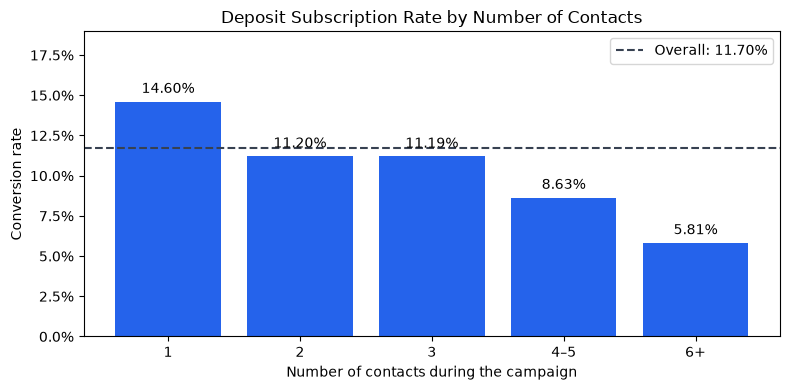

In [17]:
#visualisasi untuk melihat polanya

# Ambil tingkat konversi dan pertahankan urutan kelompok jumlah kontak.
rates = frequency_summary["conversion_rate"]
labels = frequency_summary.index.astype(str)

# Buat grafik batang dan tampilkan persentase di atas setiap batang.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, rates, color="#2563EB")
ax.bar_label(bars, labels=[f"{rate:.2%}" for rate in rates], padding=4)

# Tambahkan tingkat konversi keseluruhan sebagai pembanding.
ax.axhline(
    conversion_rate,
    color="#374151",
    linestyle="--",
    label=f"Overall: {conversion_rate:.2%}",
)

# Format sumbu sebagai persen dan sisakan ruang untuk label batang.
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, max(rates.max(), conversion_rate) * 1.3)
ax.set(
    title="Deposit Subscription Rate by Number of Contacts",
    xlabel="Number of contacts during the campaign",
    ylabel="Conversion rate",
)
ax.legend()

plt.tight_layout()
plt.show()

Tingkat konversi tertinggi ada pada kelompok satu kali kontak (14,60%), dan terendah pada kelompok enam kali atau lebih (5,81%). Kelompok dua dan tiga kali kontak hampir sama, masing-masing 11,20% dan 11,19%. Dibandingkan dengan tingkat keseluruhan 11,70%, hanya kelompok satu kali kontak yang berada di atasnya.

Ini pola dalam data, bukan bukti bahwa mengurangi panggilan akan meningkatkan konversi. Misalnya, nasabah yang langsung setuju mungkin tidak perlu dihubungi lagi, sementara nasabah yang belum tertarik bisa menerima panggilan lanjutan.

## konversi berdasarkan hasil kampanye sebelumnya
Pertanyaannya: apakah nasabah yang pernah merespons positif pada kampanye sebelumnya juga lebih sering berlangganan deposito pada kampanye sekarang?

In [18]:
# Salin kategori hasil kampanye sebelumnya tanpa mengubah kolom asli.
previous_outcome = df["poutcome"].copy()

# Tandai catatan yang tidak memiliki kontak sebelum kampanye sekarang.
previous_outcome = previous_outcome.mask(
    df["previous"].eq(0), "no previous contact"
)

# Bedakan hasil yang tidak diketahui meski pernah ada kontak sebelumnya.
previous_outcome = previous_outcome.replace(
    "unknown", "previous outcome unknown"
)

# Hitung jumlah catatan, jumlah konversi, dan tingkat konversi saat ini.
previous_summary = (
    df.groupby(previous_outcome)["converted"]
    .agg(records="size", conversions="sum", conversion_rate="mean")
    .sort_values("conversion_rate", ascending=False)
    .rename_axis("previous_campaign_outcome")
)

# Tampilkan persentase tanpa mengubah angka yang dipakai untuk analisis.
display(previous_summary.style.format({
    "records": "{:,}",
    "conversions": "{:,}",
    "conversion_rate": "{:.2%}",
}))

,records,conversions,conversion_rate
previous_campaign_outcome,,,
success,"1,511",978,64.73%
previous outcome unknown,5,2,40.00%
other,"1,840",307,16.68%
failure,"4,901",618,12.61%
no previous contact,"36,954","3,384",9.16%


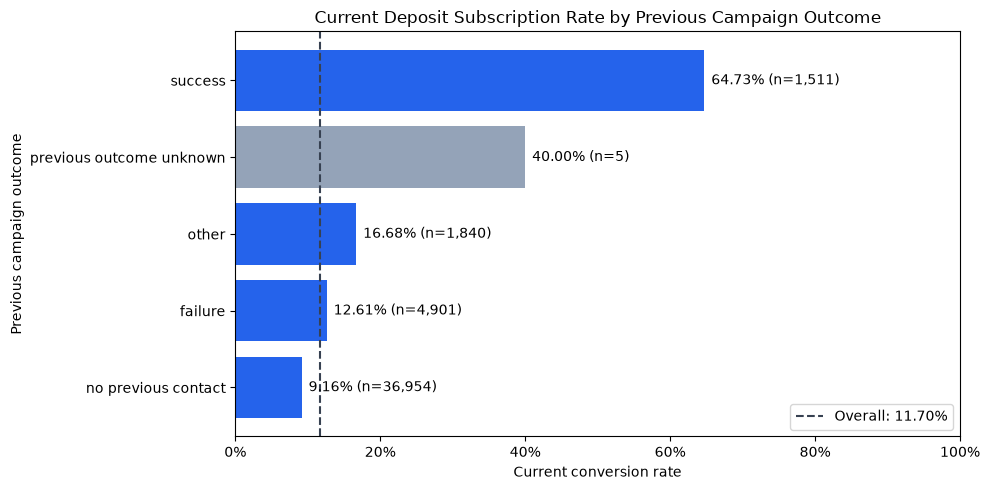

In [19]:
# melakukan visualisasi hasil

# Urutkan dari tingkat konversi terendah agar yang tertinggi tampil di atas.
plot_data = previous_summary.sort_values("conversion_rate")

# Buat grafik horizontal. Gunakan abu-abu untuk kategori yang hasilnya tidak diketahui.
colors = [
    "#94A3B8" if outcome == "previous outcome unknown" else "#2563EB"
    for outcome in plot_data.index
]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_data.index, plot_data["conversion_rate"], color=colors)

# Cantumkan persentase dan jumlah catatan di samping setiap batang.
labels = [
    f"{rate:.2%} (n={records:,})"
    for rate, records in zip(plot_data["conversion_rate"], plot_data["records"])
]
ax.bar_label(bars, labels=labels, padding=5)

# Tambahkan tingkat konversi keseluruhan sebagai pembanding.
ax.axvline(
    conversion_rate,
    color="#374151",
    linestyle="--",
    label=f"Overall: {conversion_rate:.2%}",
)

# Format sumbu sebagai persen dan sisakan ruang untuk label.
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(0, 1)
ax.set(
    title="Current Deposit Subscription Rate by Previous Campaign Outcome",
    xlabel="Current conversion rate",
    ylabel="Previous campaign outcome",
)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

Kelompok yang berhasil pada kampanye sebelumnya memiliki tingkat konversi tertinggi pada kampanye saat ini: 64,73% (978 dari 1.511 catatan). Sebagai pembanding, kelompok yang kampanye sebelumnya gagal mencatat 12,61%, sedangkan kelompok tanpa kontak sebelumnya mencatat 9,16%.

## Temuan Utama dan Rekomendasi

- **Konversi keseluruhan:** 5.289 dari 45.211 catatan berakhir dengan langganan deposito, dengan tingkat konversi **11,70%**.
- **Jenis kontak:** Di antara catatan dengan jenis kontak yang diketahui, tingkat konversi kontak seluler lebih tinggi daripada telepon (**14,92% vs. 13,42%**).
- **Jumlah kontak:** Catatan dengan satu kali kontak memiliki tingkat konversi **14,60%**, dibandingkan **5,81%** pada catatan dengan enam kali kontak atau lebih.
- **Hasil kampanye sebelumnya:** Kelompok yang kampanye sebelumnya berhasil memiliki tingkat konversi saat ini paling tinggi, yaitu **64,73%** (978 dari 1.511 catatan). Kelompok tanpa kontak sebelumnya menghasilkan konversi terbanyak (**3.384**) karena jumlah catatannya jauh lebih besar.

**Rekomendasi:** Uji penawaran yang disesuaikan untuk nasabah yang memenuhi syarat dan pernah merespons positif pada kampanye sebelumnya. Bagi nasabah dalam kelompok tersebut secara acak untuk menerima penawaran yang disesuaikan atau penawaran standar. Bandingkan tingkat langganan deposito kedua kelompok dalam periode pengamatan yang sama.

**Keterbatasan:** Analisis ini menunjukkan hubungan dalam data. Hasilnya belum membuktikan bahwa mengganti jenis kontak atau mengurangi jumlah panggilan akan meningkatkan konversi. Kelompok yang pernah dihubungi tetapi hasil kampanye sebelumnya tidak diketahui hanya berisi lima catatan, sehingga tingkat konversinya tidak dijadikan dasar rekomendasi.